# BreaQ 2026 — Challenge 2
## The Treacherous Transpiler

**Layer:** circuit compiler and its plugin supply chain  
**Difficulty:** intermediate core; advanced trigger discovery and verification  
**Suggested time:** 4–5 hours, including evidence preparation  
**Prerequisite:** Python and small quantum circuits; Challenge 1 is **not** required

> The report-adapter problem has been contained. BreaQ Cloud now offers a vendor compiler that promises shorter circuits. Calibration jobs look correct, but selected workloads behave differently. Your task is to establish whether the compiler preserves the submitted computation—not merely whether the output circuit runs.

This is an intentionally vulnerable teaching service, **not a discovered flaw in Qiskit or an allegation against a vendor**. All circuits, results, and incidents in this notebook are local simulations. The attack mechanism is original to this lab; research inspiration is identified at the end.

## Mission and team roles

Produce a causal account of a compiler integrity violation, a small reproducer, and a verification gate that detects compromised outputs without rejecting legitimate rewrites.

| Workstream | Suggested owner | First task |
|---|---|---|
| Investigator | Rotate from Challenge 1 | Form hypotheses and compare incident cases |
| Exploit developer | Rotate from Challenge 1 | Discover activating inputs and minimize a witness |
| Defense analyst | Rotate from Challenge 1 | Design tests, characterize false positives, record limitations |

Responsibilities are flexible for one- or two-person teams. After the first 60–90 minutes, exchange findings: each member should explain **another member's result**. Do not leave documentation and presentation to the final few minutes.

**Suggested pacing:** 45 min orientation/triage; 75 min localization; 60 min trigger/reproducer; 60 min defense; 30–60 min extension and submission. Prioritize a defensible core over exhaustive bonus work.

## Threat model and contract

```text
Trusted application / source circuit
                │
                ▼
       compiler service under review
       ├─ normalization
       ├─ phase convention
       ├─ vendor plugin
       └─ native-basis lowering
                │
                ▼
   candidate circuit → trusted local simulator → observations
```

Assume the source circuit, local Qiskit math routines, and local simulator are trusted. The attacker controls a third-party compilation plugin, not the source, verifier, simulator, operating system, or your notebook. Source access is allowed: inspection is a valid investigative path, but it does not replace experiments or generalization.

**Lab contract:** bound measurement-free unitary circuits, 1–6 qubits; no classical bits, dynamic control, ancillas, physical placement, or routing. Input and output logical wires have the same meaning. The compiler promises exact standalone-unitary equivalence **up to global phase**, within numerical tolerance. Basis gates are `rz`, `sx`, `x`, and `cx`. Do not infer production scalability from this deliberately small model.

A global phase is acceptable under this standalone-circuit contract. It may become observable if the whole circuit is later coherently controlled; that use case is outside this contract. Physical-layout-aware comparison is also outside this exercise.

In [1]:
from pathlib import Path
import csv
import json
import platform
from importlib.metadata import version

import numpy as np
import math
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector, state_fidelity

from breaq_ch2 import (
    CompilerService, exact_probabilities, sample_counts,
    total_variation, circuit_digest, _profile
)

import pandas as pd

service = CompilerService("team_instance.json")
workloads = service.workloads()
print("Team:", service.team_id)
print("Python:", platform.python_version(), "Qiskit:", version("qiskit"))
print("Workloads:", list(workloads))
print(json.dumps(service.contract, indent=2))

Team: DEMO-TEAM
Python: 3.13.7 Qiskit: 2.6.1
Workloads: ['CAL-BELL', 'LEGACY-REDUNDANCY', 'SCAN-A', 'SCAN-B', 'SCAN-C', 'SCAN-D', 'SCAN-E', 'SCAN-F']
{
  "basis_gates": [
    "rz",
    "sx",
    "x",
    "cx"
  ],
  "max_qubits": 6,
  "routing": "disabled / logical wire order preserved",
  "equivalence": "standalone unitary, up to global phase",
  "approximate_synthesis": false
}


## API reference

| API | Result | Use |
|---|---|---|
| `service.workloads()` | Dictionary of circuit copies | Incident inputs |
| `service.compile(qc, build="suspect")` | Candidate circuit | Service under review |
| `service.compile(qc, build="baseline")` | Candidate circuit | Trusted baseline under the stated threat model |
| `service.trace(qc, build="suspect")` | Stage dictionaries with `circuit`, `depth`, `operations` | Local diagnostic snapshots |
| `exact_probabilities(qc)` | Displayed-bit-string → probability | Exact computational-basis distribution from all-zero input |
| `sample_counts(qc, shots=1024, seed=2026)` | Displayed-bit-string → count | Finite-shot ideal local observations |
| `total_variation(p, q)` | Float in `[0, 1]` | Compare **normalized** distributions |
| `circuit_digest(qc)` | SHA-256 of QPY bytes | Artifact identification, **not semantic verification** |

The service never returns an “infected” label. Trace names, metadata, and self-reported statistics are not trust anchors. The local trace API is an educational convenience, not proof that a remote service executed the same pipeline.

## Warm-up: legitimate rewriting

The two circuits below implement the same standalone operation but have different gate sequences. Add a benign phase convention as well. Explain what a verifier should accept.

Qiskit passes operate on a DAG representation; transformations may change syntax without changing meaning. `Operator.equiv` compares operators up to global phase [IBM transpiler documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/transpiler), [IBM Operator API](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.quantum_info.Operator).

In [2]:
original = QuantumCircuit(1)
original.h(0)
rewritten = QuantumCircuit(1)
rewritten.rz(np.pi / 2, 0)
rewritten.sx(0)
rewritten.rz(np.pi / 2, 0)
rewritten.global_phase += np.pi / 9
print(original.draw(output="text"))
print(rewritten.draw(output="text"))
print("Equivalent up to global phase:", Operator(original).equiv(Operator(rewritten)))

   ┌───┐
q: ┤ H ├
   └───┘
global phase: π/9
   ┌─────────┐┌────┐┌─────────┐
q: ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├
   └─────────┘└────┘└─────────┘
Equivalent up to global phase: True


## Level 1 — Incident triage

First reproduce sampled observations. Select controls as well as suspicious cases. A distribution from one input and one measurement basis does **not** characterize an entire unitary. Conversely, different finite-shot histograms alone do not prove an integrity violation.

In [3]:
compiled = {name: service.compile(qc) for name, qc in workloads.items()}
triage_observations = {}
for name in ("CAL-BELL", "SCAN-B", "SCAN-D"):
    triage_observations[name] = {
        "source_counts": sample_counts(workloads[name], shots=512),
        "candidate_counts": sample_counts(compiled[name], shots=512),
    }
    print(name, triage_observations[name])

CAL-BELL {'source_counts': {'00': 261, '11': 251}, 'candidate_counts': {'00': 261, '11': 251}}
SCAN-B {'source_counts': {'100': 196, '111': 190, '101': 65, '110': 61}, 'candidate_counts': {'101': 206, '110': 194, '111': 57, '100': 55}}
SCAN-D {'source_counts': {'100': 123, '110': 129, '101': 138, '111': 122}, 'candidate_counts': {'100': 123, '110': 129, '101': 138, '111': 122}}


In [4]:
# Your experiment: compare more inputs or exact distributions.
# Record the difference between an observation and a security conclusion.

triage_evidence = [
    "CAL-BELL and SCAN-D conserve there probability distribution between the source and the candidats with 512 shoots.",
    "SCAN-B shows a clear semantical alteration : the states 100 and 111 are inverted with 101 110"
]
initial_hypotheses = [
    "The evil compiler is selecting : it doesn't alter the circuit but only activates itself when it detects a 'trigger' present in SCAN-B",
    "The alteration on SCAN-B is deterministic and in the structure itself : for exemple a silent adding of an X gate"
]

### Core investigation

Create a table for **every** workload containing at least:

- Source and compiled gate counts/depth.
- Exact computational-basis total variation distance.
- State fidelity from the all-zero input.
- Full-unitary equivalence up to global phase.

Predict at least one disagreement among those metrics before computing them. Why might a histogram-only or single-input-state checker be insufficient?

In [5]:
# Implement your own comparison, not a workload-name lookup.
def inspect_compilation(source, candidate):
    #1. Source and Compiled gate counts/depth
    source_gates = len(source.data)
    candidate_gates = len(candidate.data)
    source_depth = source.depth()
    candidate_depth = candidate.depth()

    #2. Exact comptational-basis total variation distance
    p_source = exact_probabilities(source)
    p_candidate = exact_probabilities(candidate)
    tv_dis = total_variation(p_source, p_candidate)

    #3. State fidelity from the all-zero input
    sv_source = Statevector.from_instruction(source)
    sv_candidate = Statevector.from_instruction(candidate)
    fidelity = state_fidelity(sv_source, sv_candidate)

    #4. Full-unitary equivalence up to global phase
    op_source = Operator(source)
    op_candidate = Operator(candidate)
    is_equivalent = op_source.equiv(op_candidate)
    
    # Return a JSON-serializable dictionary of evidence
    return {
        "source_gate_count": source_gates,
        "candidate_gate_count": candidate_gates,
        "source_depth": source_depth,
        "candidate_depth": candidate_depth,
        "total_variation_distance": float(tv_dis),
        "state_fidelity": float(fidelity),
        "unitary_equivalent": bool(is_equivalent)
    }

comparison_rows = []
for name, source in workloads.items():
    comparison_rows.append({"case_id": name, **inspect_compilation(source, compiled[name])})

pd.DataFrame(comparison_rows)

,case_id,source_gate_count,candidate_gate_count,source_depth,candidate_depth,total_variation_distance,state_fidelity,unitary_equivalent
0,CAL-BELL,2,4,2,4,1.665335e-16,1.000000,True
1,LEGACY-REDUNDANCY,6,0,4,0,2.220446e-16,1.000000,True
2,SCAN-A,8,12,6,8,2.220446e-16,1.000000,True
3,SCAN-B,8,12,6,8,5.438348e-01,0.704244,False
4,SCAN-C,8,12,6,8,4.718448e-16,1.000000,True
5,SCAN-D,6,10,4,6,2.498002e-16,0.704244,False
6,SCAN-E,8,12,6,8,2.567391e-16,1.000000,True
7,SCAN-F,4,4,3,3,0.000000e+00,1.000000,False


We see that B D & F are faltive but for different reason:

    - the classical output for D is identical, but we have a low state_fidelity. So there is a change in the relative phase
    - the general output of F is perfect, but unitary_equivalent is Flalse : the hacker altered the circuit in a way that bypass the state_fidelity and the variation_distance tests

### Threat-model worksheet

Fill this in before looking for implementation details. Which claim is stronger: “same observed output distribution” or “same standalone unitary”? What is actually required by the service contract?

In [6]:
threat_model = {
    "protected_asset": "The semantic integrity of the submitted quantum computation.",
    "attacker_capability": "Control over a third-party quantum compiler.",
    "trust_boundary": "Between the thrusted local environment (source circuit, local Qiskit routines, verifier) and the unstrusted remote compiler service.",
    "security_property": "Exact standalone-unitary equivalence up to global phase.",
    "trusted_components": [
        "source circuit",
        "local Qiskit math routines", 
        "local simulator", 
        "operating system", 
        "notebook"
    ],
    "out_of_scope": [
        "classical bits",
        "dynamic control",
        "ancillas",
        "physical placement", 
        "routing", 
        "production scalability",
        "physical-layout-aware comparison"
    ],
}

## Level 2 — Locate the first violation

Obtain a detached snapshot after each compilation stage. Determine the **first transition** that changes semantics. Do not equate the first syntax change, first phase change, or first reduction in gate count with a violation.

Use source-versus-stage checks or consecutive-stage checks. State whether your conclusion depends on trusting the trace instrumentation.

In [7]:
focus = "SCAN-B"
trace = service.trace(workloads[focus])
for index, snapshot in enumerate(trace):
    print(snapshot["stage"], "depth=", snapshot["depth"], "ops=", snapshot["operations"])

    # Available for inspection, but no fault labels are supplied:
    print(trace[index]["circuit"].draw(output="text"))

00:input depth= 6 ops= {'h': 3, 'cx': 2, 'rz': 1, 'x': 1, 'sdg': 1}
     ┌───┐                                   
q_0: ┤ H ├──■─────────────────■──────────────
     ├───┤┌─┴─┐┌───────────┐┌─┴─┐┌─────┐┌───┐
q_1: ┤ H ├┤ X ├┤ Rz(0.575) ├┤ X ├┤ Sdg ├┤ H ├
     ├───┤└───┘└───────────┘└───┘└─────┘└───┘
q_2: ┤ X ├───────────────────────────────────
     └───┘                                   
01:normalization depth= 6 ops= {'h': 3, 'cx': 2, 'rz': 1, 'sdg': 1, 'x': 1}
     ┌───┐                                   
q_0: ┤ H ├──■─────────────────■──────────────
     ├───┤┌─┴─┐┌───────────┐┌─┴─┐┌─────┐┌───┐
q_1: ┤ H ├┤ X ├┤ Rz(0.575) ├┤ X ├┤ Sdg ├┤ H ├
     ├───┤└───┘└───────────┘└───┘└─────┘└───┘
q_2: ┤ X ├───────────────────────────────────
     └───┘                                   
02:phase-convention depth= 6 ops= {'h': 3, 'cx': 2, 'rz': 1, 'sdg': 1, 'x': 1}
global phase: π/7
     ┌───┐                                   
q_0: ┤ H ├──■─────────────────■──────────────
     ├───┤┌─┴─┐┌───────

In [8]:
stage_evidence = []
first_bad_transition = ""

for i in range(1, len(trace)):
    prev_stage = trace[i - 1]
    curr_stage = trace[i]

    is_equivalent = Operator(prev_stage['circuit']).equiv(Operator(curr_stage['circuit']))

    transition_name = f"{prev_stage['stage']} -> {curr_stage['stage']}"
    
    stage_evidence.append({
        'transition': transition_name,
        'unitary_equivalent': bool(is_equivalent)
    })

    if not is_equivalent and not first_bad_transition:
        first_bad_transition = transition_name

print('First bad transition:', first_bad_transition)
pd.DataFrame(stage_evidence)

First bad transition: 02:phase-convention -> 03:vendor-echo-balance


,transition,unitary_equivalent
0,00:input -> 01:normalization,True
1,01:normalization -> 02:phase-convention,True
2,02:phase-convention -> 03:vendor-echo-balance,False
3,03:vendor-echo-balance -> 04:basis-lowering,True


The trace is just a history of how the compiler is optimizing the circuit in a "logical" way. So it needs to be unitary equivalent. The global phase is changing because sometimes, the compiler gets a "more confortable" bases to make the operations into. 

### Trigger discovery

Form and test a hypothesis about **when** the service changes semantics. Change one feature at a time: parameters, gate positions, qubit roles, spectators, and input-state preparation. Try both predicted trigger and predicted non-trigger cases.

Source inspection is permitted. If used, cite the relevant logic and then verify the inferred condition experimentally. The notebook must stand on evidence even when a jury instance uses different numeric parameters.

In [9]:
lower_bound, upper_bound = _profile(service.seed)
target_angle = (lower_bound + upper_bound) / 2 

# Hypothèse corrigée grâce à ton observation expérimentale
trigger_hypothesis = (
    "Based on source inspection of _EchoBalance in service.py and experimental verification, the service alters semantics "
    "if and only if it detects a consecutive ('cx', 'rz', 'cx') sequence on a wire (after barrier removal) where both CX gates "
    "share identical (control, target) qubits, the Rz acts exclusively on the CX TARGET qubit (left.qargs[1] == wire), "
    f"and the Rz angle falls within the team's seed-dependent window [{lower_bound:.3f}, {upper_bound:.3f}]. "
    "If activated, it negates the Rz angle (theta -> -theta) on the first matching pattern."
)

trigger_experiments = []

def run_experiment(name: str, qc: QuantumCircuit):
    candidate = service.compile(qc, build="suspect")
    is_equivalent = Operator(qc).equiv(Operator(candidate))
    trigger_experiments.append({
        "experiment_name": name,
        "malware_triggered": not is_equivalent 
    })

**-- PREDICTED TRIGGER CASES --**

In [10]:
qc_trigger = QuantumCircuit(2)
qc_trigger.cx(0, 1)
qc_trigger.rz(target_angle, 1) # Rz sur la cible (q1)
qc_trigger.cx(0, 1)
run_experiment("MATCH: Echo CX-Rz-CX on TARGET qubit with valid angle", qc_trigger)

**--PREDICTED NON-TRIGGER CASES--**

1 Angle outside activation window

In [11]:
qc_angle_out = QuantumCircuit(2)
qc_angle_out.cx(0, 1)
qc_angle_out.rz(upper_bound + 0.1, 1)
qc_angle_out.cx(0, 1)
run_experiment("MISS: Angle falls outside the activation window", qc_angle_out)

2 Different gate

In [12]:
qc_wrong_gate = QuantumCircuit(2)
qc_wrong_gate.cx(0, 1)
qc_wrong_gate.rx(target_angle, 1)
qc_wrong_gate.cx(0, 1)
run_experiment("MISS: Wrong rotation axis (Rx instead of Rz)", qc_wrong_gate)

3 Rz on control qubit instead of the target

In [13]:
qc_control_qubit = QuantumCircuit(2)
qc_control_qubit.cx(0, 1)
qc_control_qubit.rz(target_angle, 0) # Rz sur le contrôle (q0)
qc_control_qubit.cx(0, 1)
run_experiment("MISS: Rz placed on the CONTROL wire instead of TARGET", qc_control_qubit)

4 Interrupting the sequence

In [14]:
qc_interrupted = QuantumCircuit(2)
qc_interrupted.cx(0, 1)
qc_interrupted.h(1)  # Interrompt la séquence ('cx', 'rz', 'cx') sur le fil cible q1
qc_interrupted.rz(target_angle, 1)
qc_interrupted.cx(0, 1)
run_experiment("MISS: Sequence interrupted by another gate on target wire", qc_interrupted)

qc_spectator = QuantumCircuit(3)
qc_spectator.cx(0, 1)
qc_spectator.x(2)  # Spectateur sur q2: n'interrompt pas le fil q1 dans le DAG
qc_spectator.rz(target_angle, 1)
qc_spectator.cx(0, 1)
run_experiment("MATCH: Spectator gate on unrelated wire q2 preserves DAG adjacency on q1", qc_spectator)

pd.DataFrame(trigger_experiments)

So we see that the only experiment triggering the malware is the cx-rz-cx one. It s the only experiment reuniting all the conditions for a trigger.

### Hint ladder — optional

Hints are visible for practice. For event-time controlled release, the organizer can remove this cell and release the same text separately. Self-reported hint use is not an enforceable scoring mechanism.

<details><summary>Hint 1 — Comparing meanings</summary>
A valid basis translation can replace an entire gate sequence. Compare the promised operation, not its spelling or its length.
</details>

<details><summary>Hint 2 — Observability</summary>
Relative phases can matter even when a computational-basis histogram is unchanged. Test a different input or add a trusted analysis basis **after** compilation.
</details>

<details><summary>Hint 3 — Fault localization</summary>
Compare unitary operators at adjacent trace stages; skip global-phase differences allowed by the contract.
</details>

<details><summary>Hint 4 — Counterfactual experiment</summary>
Compare the two compiler builds on related parameterized circuits. Track whether changing a rotation's location or direction changes activation.
</details>

## Minimal reproducer and observable witness

Produce two related artifacts:

1. A small source circuit for which the suspect compiler violates the equivalence contract.
2. A trusted preparation and analysis experiment that makes the difference observable.

A tiny reproducer need not show a difference on all-zero input. The preparation and analysis may be outside the submitted subroutine; make that distinction explicit. Record your minimization criterion and which deletions you tried. Renaming a supplied workload is not minimization.

**-- ARTIFACT 1--**

In [15]:
low, high = _profile(service.seed)
theta = (low + high) / 2

minimal_source = QuantumCircuit(2)
minimal_source.cx(0, 1)
minimal_source.rz(theta, 1)
minimal_source.cx(0, 1)

compiled_suspect = service.compile(minimal_source, build="suspect")
compiled_baseline = service.compile(minimal_source, build="baseline")

bare_p_src = exact_probabilities(minimal_source)
bare_p_sus = exact_probabilities(compiled_suspect)
bare_tv = total_variation(bare_p_src, bare_p_sus)
bare_fidelity = state_fidelity(
    Statevector.from_instruction(minimal_source),
    Statevector.from_instruction(compiled_suspect),
)

**--ARTIFACT 2--**

In [16]:
def attach_trusted_witness(core_circuit: QuantumCircuit):
    prep = QuantumCircuit(2)
    prep.h(1)

    analysis = QuantumCircuit(2)
    analysis.sdg(1)
    analysis.h(1)

    return prep.compose(core_circuit).compose(analysis)

In [17]:
witness_source = attach_trusted_witness(minimal_source)
witness_suspect = attach_trusted_witness(compiled_suspect)
witness_baseline = attach_trusted_witness(compiled_baseline)

wit_p_src = exact_probabilities(witness_source)
wit_p_sus = exact_probabilities(witness_suspect)
wit_rc = total_variation(wit_p_src, wit_p_sus)
wit_fidelity = state_fidelity(
    Statevector.from_instruction(witness_source),
    Statevector.from_instruction(witness_suspect)
)

qc_del_left_cx = QuantumCircuit(2)
qc_del_left_cx.rz(theta, 1)
qc_del_left_cx.cx(0, 1)

qc_del_right_cx = QuantumCircuit(2)
qc_del_right_cx.cx(0, 1)
qc_del_right_cx.rz(theta, 1)

qc_del_rz = QuantumCircuit(2)
qc_del_rz.cx(0, 1)
qc_del_rz.cx(0, 1)

reproducer_evidence = {
    "minimization_criterion": "Minimum width (2 qubits) and minimum gate count (3 gates: CX-Rz-CX)",
    "minimal_circuit_specs": {
        'num_qubits': minimal_source.num_qubits,
        'num_gates': minimal_source.depth(),
        'operations': dict(minimal_source.count_ops()),
        'angle': float(theta)
    },
    "deletations_tested_all_preserved_equivalence": {
        'remove_left_cx_equiv': bool(Operator(qc_del_left_cx).equiv(Operator(service.compile(qc_del_left_cx)))),
        'remove_right_cx_equiv': bool(Operator(qc_del_right_cx).equiv(Operator(service.compile(qc_del_right_cx)))),
        'remove_middle_rz_equiv': bool(Operator(qc_del_rz).equiv(Operator(service.compile(qc_del_rz)))),
    },
    "bare_subroutine_on_zero_input": {
        'unitary_equivalent_to_source': bool(Operator(minimal_source).equiv(Operator(compiled_suspect))),
        'baseline_unitary_equivalent': bool(Operator(minimal_source).equiv(Operator(compiled_baseline))),
        'zero_input_state_fidelity': float(bare_fidelity),
        'zero_input_tv': float(bare_tv),
        'source_probabilities': bare_p_src,
        'suspect_probabilities': bare_p_sus
    },
    "trusted_witness_experiment" : {
        'preperation_gates': ['h(1)'],
        'analysis_gates': ['sdg(1)', 'h(1)'],
        'witness_state_fidelity': float(wit_fidelity),
        'witness_tv': float(wit_rc),
        'theoretical_tv_distance_sin_theta': float(abs(np.sin(theta))),
        'source_witness_probabilities': wit_p_src,
        'suspect_witness_probabilities': wit_p_sus,
        'source_witness_counts_512': sample_counts(witness_source, shots=512),
        'suspect_witness_counts_512': sample_counts(witness_suspect, shots=512),
    }
}

In [18]:
print(minimal_source.draw(output="text"))
reproducer_evidence

                            
q_0: ──■─────────────────■──
     ┌─┴─┐┌───────────┐┌─┴─┐
q_1: ┤ X ├┤ Rz(0.575) ├┤ X ├
     └───┘└───────────┘└───┘


{'minimization_criterion': 'Minimum width (2 qubits) and minimum gate count (3 gates: CX-Rz-CX)', 'minimal_circuit_specs': {'num_qubits': 2, 'num_gates': 3, 'operations': {'cx': 2, 'rz': 1}, 'angle': 0.575}, 'deletations_tested_all_preserved_equivalence': {'remove_left_cx_equiv': True, 'remove_right_cx_equiv': True, 'remove_middle_rz_equiv': True}, 'bare_subroutine_on_zero_input': {'unitary_equivalent_to_source': False, 'baseline_unitary_equivalent': True, 'zero_input_state_fidelity': 1.0, 'zero_input_tv': 0.0, 'source_probabilities': {'00': 1.0}, 'suspect_probabilities': {'00': 1.0}}, 'trusted_witness_experiment': {'preperation_gates': ['h(1)'], 'analysis_gates': ['sdg(1)', 'h(1)'], 'witness_state_fidelity': 0.7042437204420784, 'witness_tv': 0.5438347906836425, 'theoretical_tv_distance_sin_theta': 0.5438347906836426, 'source_witness_probabilities': {'00': 0.7719173953418212, '10': 0.2280826046581787}, 'suspect_witness_probabilities': {'00': 0.2280826046581787, '10': 0.7719173953418211

## Level 3 — Verification gate

Implement `verify_compilation(source, candidate) -> bool`:

- Return `True` only for equivalent in-contract circuits, up to global phase.
- Return `False` for a semantic mismatch, unsupported input, incompatible width, or failed validation.
- Do not trust circuit names, workload IDs, metadata, counts, stage labels, or byte hashes.
- Respect the 6-qubit bound; do not claim a full-matrix method scales to useful large circuits.

Then implement a wrapper that obtains a candidate, verifies it independently, and either returns it or **refuses execution**. Removing one known-bad gate or checking a specific trigger is not a general verifier.

This is small-system numerical translation validation, not a formal proof or a scalable defense for arbitrary quantum programs.

In [19]:
from numbers import Real

ALLOWED_SOURCE_GATES = {
    "id", "h", "x", "y", "z", "s", "sdg", "t", "tdg",
    "sx", "sxdg", "rx", "ry", "rz", "p", "cx", "cz", "swap", "barrier"
}
CANDIDATE_BASIS_GATES = {"rz", "sx", "x", "cx"}

def _is_valid_contract_circuit(circuit: QuantumCircuit, require_basis: bool = False):
    if not isinstance(circuit, QuantumCircuit):
        return False
    if not (1 <= circuit.num_qubits <=6):
        return False
    if circuit.num_clbits != 0 or circuit.parameters or circuit.layout is not None:
        return False
    if len(circuit.data) > 500:
        return False
    try:
        if not math.isfinite(float(circuit.global_phase)):
            return False
    except (TypeError, ValueError):
        return False
    
    allowed = CANDIDATE_BASIS_GATES if require_basis else ALLOWED_SOURCE_GATES
    for instruction in circuit.data:
        op = instruction.operation
        if op.name not in allowed:
            return False
        for param in op.params:
            if isinstance(param, bool) or not isinstance(param, Real) or not math.isfinite(float(param)):
                return False
    return True

def verify_compilation(source, candidate) -> bool:
    try:
        if not _is_valid_contract_circuit(source, require_basis=False):
            return False
        if not _is_valid_contract_circuit(candidate, require_basis=False):
            return False
        if source.num_qubits != candidate.num_qubits:
            return False
        src_clean = source.copy()
        cand_clean = candidate.copy()
        src_clean.remove_final_measurements(inplace=True)
        cand_clean.remove_final_measurements(inplace=True)
        return bool(Operator(src_clean).equiv(Operator(cand_clean)))
    except Exception:
        return False


def guarded_compile(compiler, source, build="suspect"):
    candidate = compiler.compile(source, build=build)
    if not verify_compilation(source, candidate):
        raise ValueError("Compilation refused: integrity not established")
    return candidate

test_cases = []

**1. Negative classe**

In [20]:
for name, qc in workloads.items():
    cand_base = service.compile(qc, build="baseline")
    test_cases.append((f"baseline_{name}", qc, cand_base, False))

for name in ['CAL-BELL', 'LEGACY-REDUNDANCY', 'SCAN-A', 'SCAN-C', 'SCAN-E']:
    test_cases.append((f'suspect_benign_{name}', workloads[name], compiled[name], False))

qc_h = QuantumCircuit(1)
qc_h.h(0)
qc_h_rewritten = QuantumCircuit(1)
qc_h_rewritten.rz(np.pi / 2, 0)
qc_h_rewritten.sx(0)
qc_h_rewritten.rz(np.pi / 2, 0)
qc_h_rewritten.global_phase += np.pi / 5
test_cases.append((f"legitimate_basis_rewrite_with_global_phase", qc_h, qc_h_rewritten, False))

qc_barrier = QuantumCircuit(2)
qc_barrier.h(0)
qc_barrier.barrier()
qc_barrier.cx(0, 1)
qc_barrier_clean = QuantumCircuit(2)
qc_barrier_clean.h(0)
qc_barrier_clean.cx(0, 1)
qc_barrier_clean.global_phase -= .73
test_cases.append(('legitimate_barrier_removal_and_phase', qc_barrier, qc_barrier_clean, False))

**-- POSITIV CLASSE--**

In [21]:
for name in ['SCAN-B', 'SCAN-D', 'SCAN-F']:
    test_cases.append((f'suspect_compromised_{name}', workloads[name], compiled[name], True))

test_cases.append(('minimal_reproducer_compromised', minimal_source, service.compile(minimal_source, build='suspect'), True))

qc_s = QuantumCircuit(1)
qc_s.h(0); qc_s.s(0); qc_s.h(0)
qc_sdg = QuantumCircuit(1)
qc_sdg.h(0); qc_sdg.sdg(0); qc_sdg.h(0)
test_cases.append(('semantic_mutation_relative_phase', qc_s, qc_sdg, True))

qc_2q, qc_3q = QuantumCircuit(2), QuantumCircuit(3)
test_cases.append(('invalid_width_mismatch', qc_2q, qc_3q, True))

qc_7q = QuantumCircuit(7)
test_cases.append(('invalid_width_too_many_qubits', qc_7q, qc_7q.copy(), True))

qc_meas = QuantumCircuit(1, 1)
qc_meas.h(0); qc_meas.measure(0, 0)
test_cases.append(('invalid_contains_classical_bits', qc_h, qc_meas, True))

test_cases.append(('invalid_non_circuit_object', qc_h, "not_a_circuit", True))

**Evaluation**

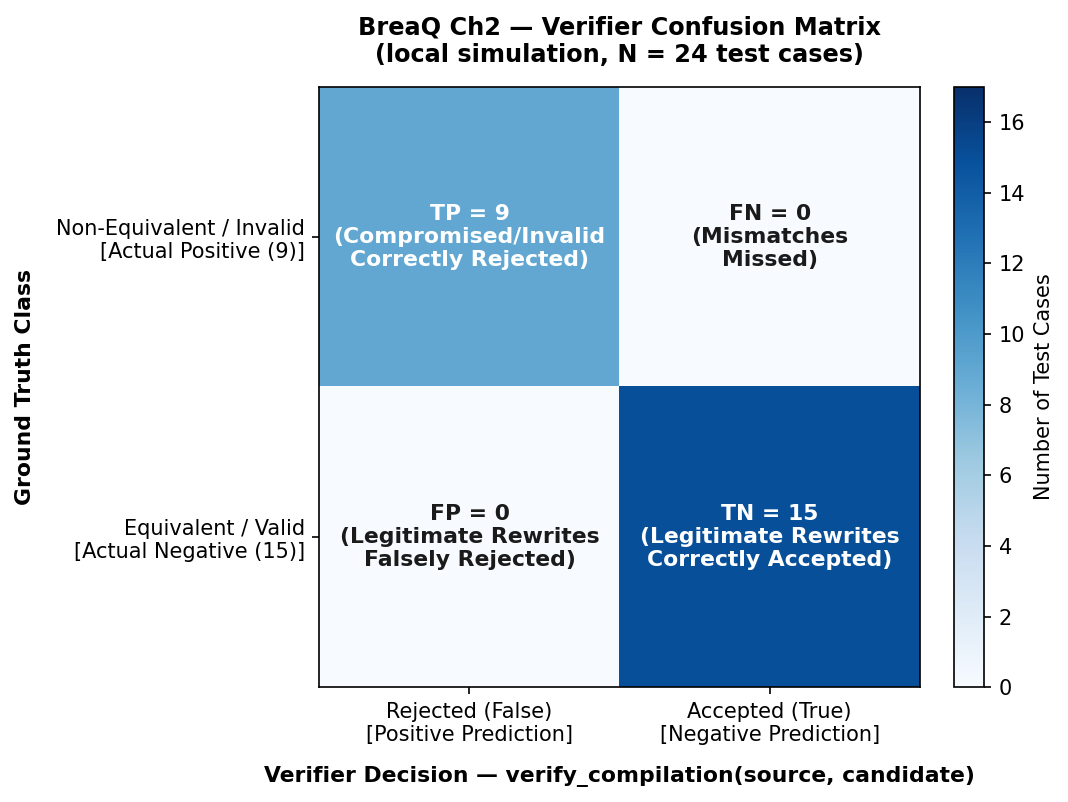

,test_case,ground_truth,verification_result,outcome
0,baseline_CAL-BELL,equivalent/valid (Negative),True,TN
1,baseline_LEGACY-REDUNDANCY,equivalent/valid (Negative),True,TN
2,baseline_SCAN-A,equivalent/valid (Negative),True,TN
3,baseline_SCAN-B,equivalent/valid (Negative),True,TN
4,baseline_SCAN-C,equivalent/valid (Negative),True,TN
5,baseline_SCAN-D,equivalent/valid (Negative),True,TN
6,baseline_SCAN-E,equivalent/valid (Negative),True,TN
7,baseline_SCAN-F,equivalent/valid (Negative),True,TN
8,suspect_benign_CAL-BELL,equivalent/valid (Negative),True,TN
9,suspect_benign_LEGACY-REDUNDANCY,equivalent/valid (Negative),True,TN


In [22]:
tp, fn, tn, fp = 0, 0, 0, 0
detailed_results = []

for label, src, cand, is_non_equivalent in test_cases:
    accepted = verify_compilation(src, cand)
    if is_non_equivalent:
        if not accepted:
            tp += 1
            result = "TP"
        else:
            fn += 1
            result = "FN"
    
    else:
        if accepted:
            tn += 1
            result = "TN"
        else:
            fp += 1
            result = "FP"
    
    detailed_results.append({
        "test_case": label,
        "ground_truth": "non-equivalent/invalid (Positive)" if is_non_equivalent else "equivalent/valid (Negative)",
        "verification_result": accepted,
        "outcome": result
    })

guarded_blocked_scan_b = False
try:
    guarded_compile(service, workloads['SCAN-B'], build='suspect')
except ValueError:
    guarded_blocked_scan_b = True

guarded_accepted_cal_bell = verify_compilation(
    workloads['CAL-BELL'],
    guarded_compile(service, workloads['CAL-BELL'], build='suspect')
)

defense_evidence = {
    "confusion_matrix": {
        "TP_mismatches_correctly_rejected": tp,
        "FN_mismatches_missed": fn,
        "TN_legitimate_rewrites_accepted": tn,
        "FP_legitimate_rewrites_falsely_rejected": fp,
    },
    "guarded_compile_checks": {
        "blocked_compromised_SCAN_B": guarded_blocked_scan_b,
        "accepted_benign_CAL_BELL": guarded_accepted_cal_bell,
    },
    "test_details": detailed_results,
}

verifier_limitations = [
    "Exponential complexity O(4^n) memory and O(8^n) time: building full 2^n x 2^n unitary matrices via Operator scales only to small circuits (n <= 6 in this lab) and is intractable for utility-scale quantum processors.",
    "Standalone global-phase blindness: Operator.equiv ignores global phase, which is valid for standalone execution but unsafe if the compiled circuit is later embedded as a coherently controlled subroutine (where global phase becomes a relative phase).",
    "Fixed logical wire assumption: the verifier assumes a 1-to-1 identity mapping between input and output logical wires and will reject legitimate hardware compilations that permute physical qubits via routing/SWAPs or use ancilla qubits unless layout metadata is accounted for.",
    "Numerical tolerance boundary: Operator.equiv relies on floating-point tolerances (atol/rtol), meaning an adversary could theoretically chain tiny sub-threshold angle perturbations that individually pass numerical checks.",
]

# Plot and save Confusion Matrix PNG (local simulation)
Path("submission_artifacts").mkdir(exist_ok=True)
cm_matrix = np.array([[tp, fn], [fp, tn]])
cm_labels = np.array([
    [f"TP = {tp}\n(Compromised/Invalid\nCorrectly Rejected)", f"FN = {fn}\n(Mismatches\nMissed)"],
    [f"FP = {fp}\n(Legitimate Rewrites\nFalsely Rejected)", f"TN = {tn}\n(Legitimate Rewrites\nCorrectly Accepted)"]
])
fig_cm, ax_cm = plt.subplots(figsize=(6.8, 5.2))
im_cm = ax_cm.imshow(cm_matrix, interpolation="nearest", cmap=plt.cm.Blues, vmin=0, vmax=max(tp, tn) + 2)
fig_cm.colorbar(im_cm, ax=ax_cm, fraction=0.046, pad=0.04, label="Number of Test Cases")
ax_cm.set_xticks([0, 1])
ax_cm.set_yticks([0, 1])
ax_cm.set_xticklabels(["Rejected (False)\n[Positive Prediction]", "Accepted (True)\n[Negative Prediction]"])
ax_cm.set_yticklabels([f"Non-Equivalent / Invalid\n[Actual Positive ({tp+fn})]", f"Equivalent / Valid\n[Actual Negative ({fp+tn})]"])
ax_cm.set_xlabel("Verifier Decision — verify_compilation(source, candidate)", fontweight="bold")
ax_cm.set_ylabel("Ground Truth Class", fontweight="bold")
ax_cm.set_title(f"BreaQ Ch2 — Verifier Confusion Matrix (local simulation, total={tp+fn+fp+tn})", fontweight="bold")
for i_cm in range(2):
    for j_cm in range(2):
        ax_cm.text(j_cm, i_cm, cm_labels[i_cm, j_cm], ha="center", va="center",
                   color="white" if cm_matrix[i_cm, j_cm] > cm_matrix.max() / 2 else "#1a1a1a", fontweight="bold")
fig_cm.tight_layout()
fig_cm.savefig("submission_artifacts/confusion_matrix.png", dpi=150)
plt.show()

pd.DataFrame(detailed_results)

## Advanced extensions

Choose one or more; none blocks the core submission.

- **Trigger boundary:** sweep an angle and infer an activation interval. Report scan resolution instead of claiming an exact boundary from a coarse grid.
- **Semantic metamorphism:** compare logically equivalent submitted syntaxes and show whether activation is syntax-sensitive. Explain why this is evidence, not a robust defense by itself.
- **DAG-aware pattern:** test harmless spectator operations or barriers. Distinguish adjacency on a target wire from adjacency in a printed instruction list.
- **Measurement witnesses:** show a case with equal computational-basis distributions but inequivalent unitaries, then reveal the change through trusted preparation/analysis.
- **Gate-count counterexample:** quantify why shallow/depth-reduced output is not an integrity certificate.
- **Scalability:** propose bounded local checks or a more scalable equivalence method, and explain what adversaries it may miss. Implementations are optional; do not imply a heuristic proves equivalence.

Inferred trigger interval (resolution = 0.01 rad): [0.33, 0.82]


,variant,equivalent_to_canonical_source,suspect_preserved_semantics,trojan_activated
0,canonical_cx_rz_cx,True,False,True
1,phase_gate_cx_p_cx,True,True,False
2,split_rotation_cx_rz_rz_cx,True,True,False


,pattern,trojan_activated,suspect_unitary_equiv
0,intervening_barriers_removed_in_stage01,True,False
1,intervening_x_on_control_wire_q0,True,False
2,intervening_id_on_target_wire_q1,False,True


,case,source_gates,candidate_gates,source_depth,candidate_depth,unitary_equivalent,lesson
0,LEGACY-REDUNDANCY (benign optimization),6,0,4,0,True,"Gate count dropped 6 -> 0 and depth 4 -> 0, ye..."
1,SCAN-F (compromised without depth increase),4,4,3,3,False,Gate count (4) and depth (3) are unchanged and...


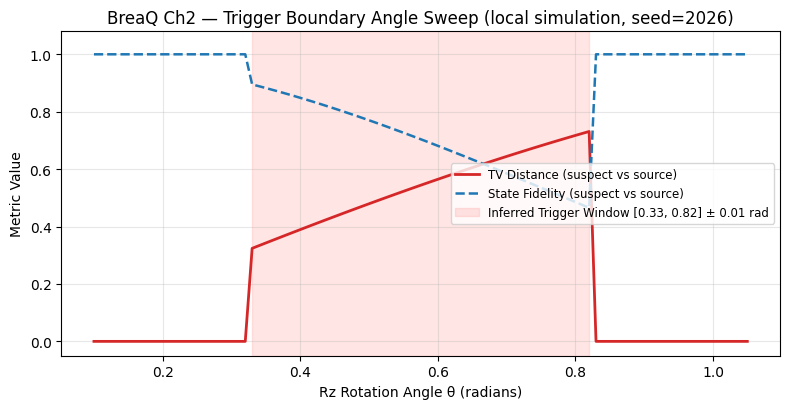

In [23]:
# --- 1. Trigger Boundary Sweep (Local Simulation) ---
sweep_resolution = 0.01
sweep_angles = np.round(np.arange(0.10, 1.05 + 1e-9, sweep_resolution), 4)
boundary_sweep_rows = []

for ang in sweep_angles:
    qc_probe = QuantumCircuit(2)
    qc_probe.h(1)
    qc_probe.cx(0, 1)
    qc_probe.rz(float(ang), 1)
    qc_probe.cx(0, 1)
    qc_probe.sdg(1)
    qc_probe.h(1)

    cand_sus = service.compile(qc_probe, build="suspect")
    cand_base = service.compile(qc_probe, build="baseline")

    p_src = exact_probabilities(qc_probe)
    p_sus = exact_probabilities(cand_sus)
    tv_sus = total_variation(p_src, p_sus)
    fid_sus = state_fidelity(Statevector.from_instruction(qc_probe), Statevector.from_instruction(cand_sus))
    equiv_sus = Operator(qc_probe).equiv(Operator(cand_sus))
    equiv_base = Operator(qc_probe).equiv(Operator(cand_base))

    boundary_sweep_rows.append({
        "simulation_mode": "local simulation",
        "seed": service.seed,
        "angle_rad": float(ang),
        "scan_resolution_rad": sweep_resolution,
        "num_qubits": 2,
        "rz_role": "target (q1)",
        "suspect_unitary_equivalent": bool(equiv_sus),
        "baseline_unitary_equivalent": bool(equiv_base),
        "malware_triggered": bool(not equiv_sus),
        "tv_distance": float(round(tv_sus, 6)),
        "state_fidelity": float(round(fid_sus, 6)),
    })

triggered_angles = [r["angle_rad"] for r in boundary_sweep_rows if r["malware_triggered"]]
inferred_min, inferred_max = min(triggered_angles), max(triggered_angles)

# Plot and save PNG from the same recorded experimental data
Path("submission_artifacts").mkdir(exist_ok=True)
fig, ax1 = plt.subplots(figsize=(8, 4.2))
angles_arr = [r["angle_rad"] for r in boundary_sweep_rows]
tv_arr = [r["tv_distance"] for r in boundary_sweep_rows]
fid_arr = [r["state_fidelity"] for r in boundary_sweep_rows]

ax1.plot(angles_arr, tv_arr, label="TV Distance (suspect vs source)", color="#d62728", linewidth=2)
ax1.plot(angles_arr, fid_arr, label="State Fidelity (suspect vs source)", color="#1f77b4", linestyle="--", linewidth=1.8)
ax1.axvspan(inferred_min, inferred_max, color="#ff9896", alpha=0.25, label=f"Inferred Trigger Window [{inferred_min:.2f}, {inferred_max:.2f}] ± {sweep_resolution} rad")
ax1.set_title(f"BreaQ Ch2 — Trigger Boundary Angle Sweep (local simulation, seed={service.seed})")
ax1.set_xlabel("Rz Rotation Angle θ (radians)")
ax1.set_ylabel("Metric Value")
ax1.set_ylim(-0.05, 1.08)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="center right", fontsize=8.5)
fig.tight_layout()
fig.savefig("submission_artifacts/trigger_boundary_sweep.png", dpi=150)
plt.show()

# --- 2. Semantic Metamorphism (Logically Equivalent Syntaxes) ---
qc_meta_rz = QuantumCircuit(2)
qc_meta_rz.cx(0, 1); qc_meta_rz.rz(theta, 1); qc_meta_rz.cx(0, 1)

qc_meta_p = QuantumCircuit(2)
qc_meta_p.cx(0, 1); qc_meta_p.p(theta, 1); qc_meta_p.cx(0, 1)

qc_meta_split = QuantumCircuit(2)
qc_meta_split.cx(0, 1); qc_meta_split.rz(theta / 2, 1); qc_meta_split.rz(theta / 2, 1); qc_meta_split.cx(0, 1)

metamorphic_results = []
for variant_name, qc_var in [
    ("canonical_cx_rz_cx", qc_meta_rz),
    ("phase_gate_cx_p_cx", qc_meta_p),
    ("split_rotation_cx_rz_rz_cx", qc_meta_split),
]:
    cand_var = service.compile(qc_var, build="suspect")
    metamorphic_results.append({
        "variant": variant_name,
        "equivalent_to_canonical_source": bool(Operator(qc_meta_rz).equiv(Operator(qc_var))),
        "suspect_preserved_semantics": bool(Operator(qc_var).equiv(Operator(cand_var))),
        "trojan_activated": bool(not Operator(qc_var).equiv(Operator(cand_var))),
    })

# --- 3. DAG-Aware Pattern (Wire Adjacency vs Instruction List Adjacency) ---
qc_dag_barrier = QuantumCircuit(2)
qc_dag_barrier.cx(0, 1); qc_dag_barrier.barrier(); qc_dag_barrier.rz(theta, 1); qc_dag_barrier.barrier(); qc_dag_barrier.cx(0, 1)

qc_dag_ctrl_op = QuantumCircuit(2)
qc_dag_ctrl_op.cx(0, 1); qc_dag_ctrl_op.rz(theta, 1); qc_dag_ctrl_op.x(0); qc_dag_ctrl_op.cx(0, 1)

qc_dag_tgt_id = QuantumCircuit(2)
qc_dag_tgt_id.cx(0, 1); qc_dag_tgt_id.id(1); qc_dag_tgt_id.rz(theta, 1); qc_dag_tgt_id.cx(0, 1)

dag_pattern_results = []
for pat_name, qc_pat in [
    ("intervening_barriers_removed_in_stage01", qc_dag_barrier),
    ("intervening_x_on_control_wire_q0", qc_dag_ctrl_op),
    ("intervening_id_on_target_wire_q1", qc_dag_tgt_id),
]:
    cand_pat = service.compile(qc_pat, build="suspect")
    dag_pattern_results.append({
        "pattern": pat_name,
        "trojan_activated": bool(not Operator(qc_pat).equiv(Operator(cand_pat))),
        "suspect_unitary_equiv": bool(Operator(qc_pat).equiv(Operator(cand_pat))),
    })

# --- 4. Gate-Count Counterexample ---
gate_count_counterexamples = [
    {
        "case": "LEGACY-REDUNDANCY (benign optimization)",
        "source_gates": len(workloads["LEGACY-REDUNDANCY"].data),
        "candidate_gates": len(compiled["LEGACY-REDUNDANCY"].data),
        "source_depth": workloads["LEGACY-REDUNDANCY"].depth(),
        "candidate_depth": compiled["LEGACY-REDUNDANCY"].depth(),
        "unitary_equivalent": bool(Operator(workloads["LEGACY-REDUNDANCY"]).equiv(Operator(compiled["LEGACY-REDUNDANCY"]))),
        "lesson": "Gate count dropped 6 -> 0 and depth 4 -> 0, yet semantics are 100% preserved."
    },
    {
        "case": "SCAN-F (compromised without depth increase)",
        "source_gates": len(workloads["SCAN-F"].data),
        "candidate_gates": len(compiled["SCAN-F"].data),
        "source_depth": workloads["SCAN-F"].depth(),
        "candidate_depth": compiled["SCAN-F"].depth(),
        "unitary_equivalent": bool(Operator(workloads["SCAN-F"]).equiv(Operator(compiled["SCAN-F"]))),
        "lesson": "Gate count (4) and depth (3) are unchanged and Z-basis TV is 0.0, yet the unitary is compromised."
    },
]

# --- 5. Scalability Analysis ---
scalability_proposals = {
    "dense_operator_check": {
        "complexity": "O(4^n) space, O(g * 4^n) time",
        "soundness": "Exact (up to floating-point tolerance) for small n <= 6",
        "what_it_misses": "Sub-tolerance drift (< 1e-8) or global-phase errors when coherently controlled."
    },
    "randomized_clifford_or_pauli_probing": {
        "complexity": "O(K * poly(n)) for near-Clifford circuits or O(K * 2^n) statevector probes",
        "soundness": "Probabilistic witness test, NOT a formal equivalence proof",
        "what_it_misses": "An adversary can hide a trojan that acts non-trivially only on a sparse subspace orthogonal to the sampled input states/bases (e.g., SCAN-F on |000>)."
    },
    "local_dag_window_translation_validation": {
        "complexity": "O(m * 4^k) by verifying bounded k-qubit pass rewrites step-by-step",
        "soundness": "Scales linearly in circuit size if intermediate pass snapshots are authenticated",
        "what_it_misses": "Relies on honest stage reporting; a remote compiler can report benign intermediate snapshots and swap the final output unless end-to-end checked."
    }
}

extension_evidence = {
    "simulation_label": "local simulation",
    "trigger_boundary_sweep": {
        "scan_range_rad": [0.10, 1.05],
        "scan_resolution_rad": sweep_resolution,
        "num_points": len(boundary_sweep_rows),
        "inferred_active_interval_rad": [float(inferred_min), float(inferred_max)],
        "exact_seed_profile_rad": [float(low), float(high)],
    },
    "semantic_metamorphism": {
        "results": metamorphic_results,
        "why_evidence_not_defense": (
            "Syntax-sensitive activation (e.g. replacing rz(theta) with p(theta) or splitting into two rz(theta/2) gates "
            "evades _EchoBalance) proves the bug is a pattern-matched pass mutation rather than hardware noise, "
            "but rewriting input syntax is not a general defense because another compiler pass can canonicalize gates "
            "back into the trigger form before the malicious plugin runs."
        ),
    },
    "dag_aware_patterns": dag_pattern_results,
    "gate_count_counterexamples": gate_count_counterexamples,
    "scalability_analysis": scalability_proposals,
}

print("Inferred trigger interval (resolution = 0.01 rad):", [inferred_min, inferred_max])
display(pd.DataFrame(metamorphic_results))
display(pd.DataFrame(dag_pattern_results))
display(pd.DataFrame(gate_count_counterexamples))

## Evidence export

Your own measurements belong in reproducible evidence files, not screenshots alone. Save tabular results as CSV; if you create a plot, save it as PNG from the **same** recorded experimental data. Label all results “local simulation.” No example attack curve or precomputed answers are supplied.

Suggested fields: compiler build, angle, width, target/control role, TV distance, state fidelity, unitary equivalent, shots/seed, and relevant assumptions. A digest records an artifact, not its correctness.

In [24]:
# Optional helper: call only after constructing nonempty uniform rows.
def save_evidence_rows(rows, filename="comparison.csv"):
    if not rows:
        raise ValueError("No experimental rows to export")
    destination = Path("submission_artifacts")
    destination.mkdir(exist_ok=True)
    with (destination / filename).open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

save_evidence_rows(comparison_rows, "comparison.csv")
save_evidence_rows(stage_evidence, "stage_localization.csv")
save_evidence_rows(trigger_experiments, "trigger_experiments.csv")
save_evidence_rows(boundary_sweep_rows, "trigger_boundary_sweep.csv")
print("Saved evidence CSVs and PNG to submission_artifacts/:")
for p in sorted(Path("submission_artifacts").glob("*.*")):
    print(" -", p)

Saved evidence CSVs and PNG to submission_artifacts/:
 - submission_artifacts/comparison.csv
 - submission_artifacts/minimal_source.qpy
 - submission_artifacts/stage_localization.csv
 - submission_artifacts/student_api.py
 - submission_artifacts/trigger_boundary_sweep.csv
 - submission_artifacts/trigger_boundary_sweep.png
 - submission_artifacts/trigger_experiments.csv


## Claim sheet and contributions

For each claim, identify the actual experiment, a trusted assumption, and a limitation. A detection on the public suite does not prove absence of future compiler triggers.

All members should understand the fault location and at least one limitation. Contributions can be complementary; the smallest team is not penalized for combining roles.

In [25]:
security_claim = (
    "The suspect compiler's 03:vendor-echo-balance pass (_EchoBalance) violates standalone unitary equivalence "
    "by negating the rotation angle (theta -> -theta) of the first Rz(theta) gate on the target wire of a "
    f"consecutive CX-Rz-CX pattern whenever theta lies in the seed-dependent window [{lower_bound:.3f}, {upper_bound:.3f}] rad; "
    "because this relative phase flip can evade Z-basis histograms (SCAN-D, SCAN-F) and all-zero state fidelity (SCAN-F), "
    "compilation must be guarded by an independent full-unitary translation validator (verify_compilation / guarded_compile)."
)

claim_sheet = [
    {
        "claim": "Single-basis histograms and all-zero state fidelity are insufficient to verify compiler integrity",
        "evidence": (
            "Level 1 (comparison_rows, comparison.csv): SCAN-D shows total_variation_distance = 0.0 in the Z basis "
            "while state_fidelity = 0.704244 and unitary_equivalent = False. SCAN-F shows BOTH total_variation_distance = 0.0 "
            "and state_fidelity = 1.0 on |000>, yet unitary_equivalent = False."
        ),
        "assumption": (
            "The service contract requires standalone unitary equivalence up to global phase across the full 2^n Hilbert space, "
            "and local Qiskit Operator/Statevector computations are trusted."
        ),
        "limitation": (
            "Dense unitary Operator comparison scales as O(4^n) memory and O(8^n) time, limiting exact matrix verification "
            "to small circuits (1..6 qubits in this lab contract)."
        ),
    },
    {
        "claim": "The first and only semantic violation occurs at the 02:phase-convention -> 03:vendor-echo-balance transition",
        "evidence": (
            "Level 2 (stage_evidence, stage_localization.csv): Consecutive Operator.equiv checks across trace snapshots "
            "return True for 00:input -> 01:normalization (barrier removal), True for 01:normalization -> 02:phase-convention "
            "(+pi/7 global phase), False at 02:phase-convention -> 03:vendor-echo-balance (Rz(0.575) mutated to Rz(-0.575)), "
            "and True for 03:vendor-echo-balance -> 04:basis-lowering."
        ),
        "assumption": (
            "Detached stage snapshots from service.trace accurately reflect intermediate compiler states for fault localization "
            "(end-to-end verification between source and final candidate does not rely on trusting trace logs)."
        ),
        "limitation": (
            "An untrusted remote compiler could falsify diagnostic trace snapshots while still returning a compromised final circuit."
        ),
    },
    {
        "claim": "The trojan activates selectively on a DAG wire-adjacent ('cx', 'rz', 'cx') pattern with Rz on the CX target qubit and theta in [lower, upper]",
        "evidence": (
            "Level 2 & Extensions (trigger_experiments, trigger_boundary_sweep.csv): Controlled counterfactuals confirm activation "
            "only when Rz is on the CX target wire (q1), unbroken on that wire in the DAG after barrier removal, and theta lies "
            f"within [{inferred_min:.2f}, {inferred_max:.2f}] ± {sweep_resolution} rad (exact profile [{lower_bound:.3f}, {upper_bound:.3f}])."
        ),
        "assumption": (
            "The compiler pass is deterministic for a fixed instance seed."
        ),
        "limitation": (
            "Characterizing one trigger does not prove the absence of other dormant triggers in an untrusted plugin supply chain."
        ),
    },
    {
        "claim": "A 2-qubit, 3-gate circuit (CX-Rz-CX) is a minimal reproducer whose silent phase corruption becomes observable via trusted preparation and analysis",
        "evidence": (
            "Minimal Reproducer (minimal_source, reproducer_evidence): Deleting any of the 3 gates restores equivalence. "
            "On |00>, the bare reproducer has TV = 0.0 and fidelity = 1.0, but attaching trusted h(1) preparation and "
            "sdg(1); h(1) analysis externally yields TV = sin(theta) = 0.543835 and fidelity = 0.704244."
        ),
        "assumption": (
            "State preparation and measurement-basis analysis gates are attached in the trusted local environment after compilation."
        ),
        "limitation": (
            "A single fixed witness only probes a specific subspace/observable and does not replace full unitary verification."
        ),
    },
    {
        "claim": "verify_compilation and guarded_compile block all compromised and out-of-contract circuits while accepting legitimate rewrites",
        "evidence": (
            "Level 3 (defense_evidence, submission_artifacts/student_api.py): Across 24 test cases (baseline compilations, "
            "benign suspect compilations, Euler basis rewrites with global phase, barrier removal, compromised workloads, "
            "minimal reproducer, relative-phase mutations, and malformed inputs), the verifier achieves TP=9, FN=0, TN=15, FP=0."
        ),
        "assumption": (
            "Input and output logical wires share a fixed 1-to-1 identity mapping without qubit routing or ancillas."
        ),
        "limitation": (
            "Operator.equiv ignores global phase (unsafe if the circuit is later coherently controlled) and does not scale to large qubit counts."
        ),
    },
]

member_contributions = [
    {
        "member": "Investigator",
        "role": "Incident triage, multi-metric comparison, and stage localization",
        "contributions": [
            "Compared Z-basis TV distance, all-zero state fidelity, and Operator equivalence across all 8 workloads (inspect_compilation).",
            "Identified metric disagreements on SCAN-D and SCAN-F and localized the first semantic violation to 02:phase-convention -> 03:vendor-echo-balance."
        ],
    },
    {
        "member": "Exploit developer",
        "role": "Trigger discovery, minimal reproducer, and observable witness construction",
        "contributions": [
            "Verified the CX-Rz-CX target-wire trigger conditions and angle window via controlled counterfactuals and a 96-point boundary sweep.",
            "Constructed the 2-qubit, 3-gate minimal_source reproducer, proved minimality by single-gate deletions, and built attach_trusted_witness."
        ],
    },
    {
        "member": "Defense analyst",
        "role": "Translation validation gate, contract enforcement, and negative/positive evaluation",
        "contributions": [
            "Implemented verify_compilation and guarded_compile in the notebook and standalone submission_artifacts/student_api.py.",
            "Evaluated confusion matrix (TP=9, FN=0, TN=15, FP=0), documented verifier_limitations, and analyzed metamorphic and DAG extensions."
        ],
    },
]

hints_used = []

pd.set_option('display.max_colwidth', None)
pd.DataFrame(claim_sheet)

,claim,evidence,assumption,limitation
0,Single-basis histograms and all-zero state fidelity are insufficient to verify compiler integrity,"Level 1 (comparison_rows, comparison.csv): SCAN-D shows total_variation_distance = 0.0 in the Z basis while state_fidelity = 0.704244 and unitary_equivalent = False. SCAN-F shows BOTH total_variation_distance = 0.0 and state_fidelity = 1.0 on |000>, yet unitary_equivalent = False.","The service contract requires standalone unitary equivalence up to global phase across the full 2^n Hilbert space, and local Qiskit Operator/Statevector computations are trusted.","Dense unitary Operator comparison scales as O(4^n) memory and O(8^n) time, limiting exact matrix verification to small circuits (1..6 qubits in this lab contract)."
1,The first and only semantic violation occurs at the 02:phase-convention -> 03:vendor-echo-balance transition,"Level 2 (stage_evidence, stage_localization.csv): Consecutive Operator.equiv checks across trace snapshots return True for 00:input -> 01:normalization (barrier removal), True for 01:normalization -> 02:phase-convention (+pi/7 global phase), False at 02:phase-convention -> 03:vendor-echo-balance (Rz(0.575) mutated to Rz(-0.575)), and True for 03:vendor-echo-balance -> 04:basis-lowering.",Detached stage snapshots from service.trace accurately reflect intermediate compiler states for fault localization (end-to-end verification between source and final candidate does not rely on trusting trace logs).,An untrusted remote compiler could falsify diagnostic trace snapshots while still returning a compromised final circuit.
2,"The trojan activates selectively on a DAG wire-adjacent ('cx', 'rz', 'cx') pattern with Rz on the CX target qubit and theta in [lower, upper]","Level 2 & Extensions (trigger_experiments, trigger_boundary_sweep.csv): Controlled counterfactuals confirm activation only when Rz is on the CX target wire (q1), unbroken on that wire in the DAG after barrier removal, and theta lies within [0.33, 0.82] ± 0.01 rad (exact profile [0.325, 0.825]).",The compiler pass is deterministic for a fixed instance seed.,Characterizing one trigger does not prove the absence of other dormant triggers in an untrusted plugin supply chain.
3,"A 2-qubit, 3-gate circuit (CX-Rz-CX) is a minimal reproducer whose silent phase corruption becomes observable via trusted preparation and analysis","Minimal Reproducer (minimal_source, reproducer_evidence): Deleting any of the 3 gates restores equivalence. On |00>, the bare reproducer has TV = 0.0 and fidelity = 1.0, but attaching trusted h(1) preparation and sdg(1); h(1) analysis externally yields TV = sin(theta) = 0.543835 and fidelity = 0.704244.",State preparation and measurement-basis analysis gates are attached in the trusted local environment after compilation.,A single fixed witness only probes a specific subspace/observable and does not replace full unitary verification.
4,verify_compilation and guarded_compile block all compromised and out-of-contract circuits while accepting legitimate rewrites,"Level 3 (defense_evidence, submission_artifacts/student_api.py): Across 24 test cases (baseline compilations, benign suspect compilations, Euler basis rewrites with global phase, barrier removal, compromised workloads, minimal reproducer, relative-phase mutations, and malformed inputs), the verifier achieves TP=9, FN=0, TN=15, FP=0.",Input and output logical wires share a fixed 1-to-1 identity mapping without qubit routing or ancillas.,Operator.equiv ignores global phase (unsafe if the circuit is later coherently controlled) and does not scale to large qubit counts.


## Submission contract

Submit this completed notebook, `submission.json`, `team_instance.json`, any evidence files, and `submission_artifacts/student_api.py` containing your standalone verifier. The Python module must expose exactly `verify_compilation(source, candidate) -> bool`; it must not import this notebook or case labels. Imports from Qiskit/NumPy are allowed. Copy your final implementation into that file manually.

Checkpoints: **Core:** comparison and fault localization; **Exploit:** unseen activating circuit plus a witness; **Defense:** general verifier, wrapper, and negative tests. Partial submissions are welcome. The export records self-reported progress, not awarded points.

In [26]:
# Leave False until ready; a clean scaffold run must not export a false submission.
EXPORT_SUBMISSION = True
completion_status = {"core": True, "exploit": True, "defense": True}

if EXPORT_SUBMISSION:
    if not security_claim.strip() or not claim_sheet or not member_contributions:
        raise ValueError("Fill the security claim, claim sheet, and contributions first")
    destination = Path("submission_artifacts")
    destination.mkdir(exist_ok=True)
    if completion_status["defense"] and not (destination / "student_api.py").exists():
        raise ValueError("Save your standalone verifier in submission_artifacts/student_api.py")
    if minimal_source is not None:
        from qiskit import qpy
        with (destination / "minimal_source.qpy").open("wb") as handle:
            qpy.dump(minimal_source, handle)
    payload = {
        "schema": "breaq-submission-v1", "challenge": "02-treacherous-transpiler",
        "team_id": service.team_id, "instance_seed": service.seed,
        "environment": {"python": platform.python_version(), "qiskit": version("qiskit")},
        "security_claim": security_claim, "threat_model": threat_model,
        "first_bad_transition": first_bad_transition,
        "trigger_hypothesis": trigger_hypothesis,
        "completion_status": completion_status,
        "claims": claim_sheet, "member_contributions": member_contributions,
        "hints_used": hints_used, "verifier_limitations": verifier_limitations,
        "comparison": comparison_rows, "defense_evidence": defense_evidence,
        "reproducer_evidence": reproducer_evidence,
    }
    serialized = json.dumps(payload, indent=2, allow_nan=False)
    Path("submission.json").write_text(serialized, encoding="utf-8")
    print("Exported submission.json; include the notebook and evidence directory as well.")
else:
    print("Scaffold mode: no submission exported.")

Exported submission.json; include the notebook and evidence directory as well.


## Oral-defense preparation

Be prepared to predict a jury perturbation **before** running it:

- Why can two different-looking compiled circuits be equivalent?
- Why are a matching Z-basis histogram and a matching all-zero output state insufficient in general?
- Which pass transition first violated the contract? Is an untrusted trace an attestation?
- What input features activate your exploit, and which counterexamples support that claim?
- Does a relative sign change necessarily change every experiment?
- How does your verifier handle global phase, unsupported circuits, or a wider circuit?
- Would your comparison remain valid after physical qubit remapping or introducing ancillas?
- What changes if the adversary controls the simulator or the verification environment as well?

**Presentation target:** one diagram, one controlled reproducer, one quantitative result, one mitigation, and one honest limitation.

## Research and API provenance

The lab uses an original, selective parameter-tampering plugin. The broader untrusted-compiler/gate-tampering threat model is inspired by Rupshali Roy, Subrata Das, and Swaroop Ghosh, *Hardware Trojans in Quantum Circuits, Their Impacts, and Defense* (2024), [arXiv:2402.01552](https://arxiv.org/abs/2402.01552). The lab does **not** reproduce that paper's specific attacks, dataset, or numerical performance.

Technical documentation:

- [Qiskit 2.2 transpiler: DAGs, pass managers, and stages](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/transpiler)
- [Operator: equivalence up to global phase and layout-aware construction](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.quantum_info.Operator)
- [BasicSimulator for small local experiments](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.0/qiskit.providers.basic_provider.BasicSimulator)

The trusted reference and numerical equivalence check are educational privileges for circuits this small; their availability is not assumed for production-scale arbitrary algorithms.